# Лабораторная работа №10. Статистические критерии в Python

**Дисциплина:** Введение в анализ больших данных  
**Цель:** применить на практике критерии Шапиро–Уилка, Фишера, Колмогорова–Смирнова, t-тест Стьюдента и критерий Пирсона χ².

**Данные (Rdatasets):** `trees`, `randu`, `ldeaths`, `HairEyeColor`.

**Инструменты:** `numpy`, `pandas`, `scipy.stats`, `matplotlib`, `seaborn`, `statsmodels`.

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.mosaicplot import mosaic

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
np.random.seed(42)

BASE = "https://vincentarelbundock.github.io/Rdatasets/csv"
OUT_DIR = "output"
os.makedirs(OUT_DIR, exist_ok=True)

ALPHA = 0.05

def hr(title=""):
    print("\n" + "=" * 78)
    if title:
        print(title)
        print("=" * 78)

def load_csv(name, local_file=None):
    """Загрузка CSV: сначала локально, потом из Rdatasets."""
    if local_file and os.path.exists(local_file):
        return pd.read_csv(local_file)
    ds, fn = name.split("/")
    return pd.read_csv(f"{BASE}/{ds}/{fn}.csv")

def f_test(a, b):
    """Двусторонний F-тест равенства дисперсий (H0: sigma1^2 = sigma2^2)."""
    a = np.asarray(a, float); b = np.asarray(b, float)
    a = a[~np.isnan(a)]; b = b[~np.isnan(b)]
    F = a.var(ddof=1) / b.var(ddof=1)
    dfn, dfd = len(a) - 1, len(b) - 1
    cdf = stats.f.cdf(F, dfn, dfd)
    p = 2 * min(cdf, 1 - cdf)
    return F, p, dfn, dfd

def verdict(p, alpha=ALPHA):
    return "H0 НЕ отвергается (p>alpha)" if p > alpha else "H0 отвергается (p<=alpha)"

---
## 1–3. Данные `trees`

### 1. Имена столбцов


### 2. Shapiro–Wilk (нормальность)
Shapiro–Wilk (Шапиро–Уилк) — тест, который проверяет: «Похоже ли распределение данных на нормальное (колокол Гаусса)?»


### 3. Критерий Фишера (равенство дисперсий)
Критерий Фишера (F-тест) — это проверка гипотезы о том, одинаково ли «разбросаны» данные в двух выборках.
Классический t-тест (Стьюдента) требует равенства дисперсий (гомоскедастичности). Если дисперсии разные — классический t-тест врёт (даёт неправильный p-value). Тогда используют


In [3]:
hr("1-3. ДАННЫЕ trees")
trees = load_csv("datasets/trees")
trees = trees.drop(columns=[c for c in trees.columns if c.lower().startswith("row")],
                   errors="ignore")

print("[1] Имена столбцов:", list(trees.columns))
trees.head()


1-3. ДАННЫЕ trees
[1] Имена столбцов: ['Girth', 'Height', 'Volume']


,Girth,Height,Volume
0,8.3,70,10.3
1,8.6,65,10.3
2,8.8,63,10.2
3,10.5,72,16.4
4,10.7,81,18.8


In [4]:
print("[2] Тест Шапиро-Уилка на нормальность")
print(f"{'столбец':<10}{'W':>10}{'p-value':>14}   вывод")
sw = {}
for col in trees.columns:
    W, p = stats.shapiro(trees[col])
    sw[col] = (W, p)
    print(f"{col:<10}{W:>10.4f}{p:>14.4g}   {verdict(p)}")

[2] Тест Шапиро-Уилка на нормальность
столбец            W       p-value   вывод
Girth         0.9412       0.08893   H0 НЕ отвергается (p>alpha)
Height        0.9655        0.4034   H0 НЕ отвергается (p>alpha)
Volume        0.8876      0.003579   H0 отвергается (p<=alpha)


**Вывод по п.2.** При `p > 0.05` нет оснований отвергать H0 о нормальности. Для `trees` выборка маленькая (n=31), поэтому тест имеет низкую мощность: чаще H0 не отвергается. При интерпретации важно помнить, что Shapiro–Wilk при малых n осторожен.

In [5]:
print("[3] Критерий Фишера: попарное сравнение дисперсий")
cols = list(trees.columns)
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        a, b = trees[cols[i]], trees[cols[j]]
        F, p, dfn, dfd = f_test(a, b)
        print(f"  {cols[i]:<8} vs {cols[j]:<8}  F={F:9.4f}  df=({dfn},{dfd})  "
              f"p={p:.4g}   {verdict(p)}")

print("\nКорреляции (для контекста):")
print(trees.corr().round(3))

[3] Критерий Фишера: попарное сравнение дисперсий
  Girth    vs Height    F=   0.2426  df=(30,30)  p=0.0002127   H0 отвергается (p<=alpha)
  Girth    vs Volume    F=   0.0364  df=(30,30)  p=1.509e-14   H0 отвергается (p<=alpha)
  Height   vs Volume    F=   0.1503  df=(30,30)  p=1.381e-06   H0 отвергается (p<=alpha)

Корреляции (для контекста):
        Girth  Height  Volume
Girth   1.000   0.519   0.967
Height  0.519   1.000   0.598
Volume  0.967   0.598   1.000


**Вывод по п.3.** Если для пары `p <= 0.05` — дисперсии значимо различаются (H0 о равенстве дисперсий отвергается). Иначе — оснований считать их разными нет. F-тест чувствителен к нарушению нормальности; при отклонении от нормальности робастнее Levene/Bartlett.

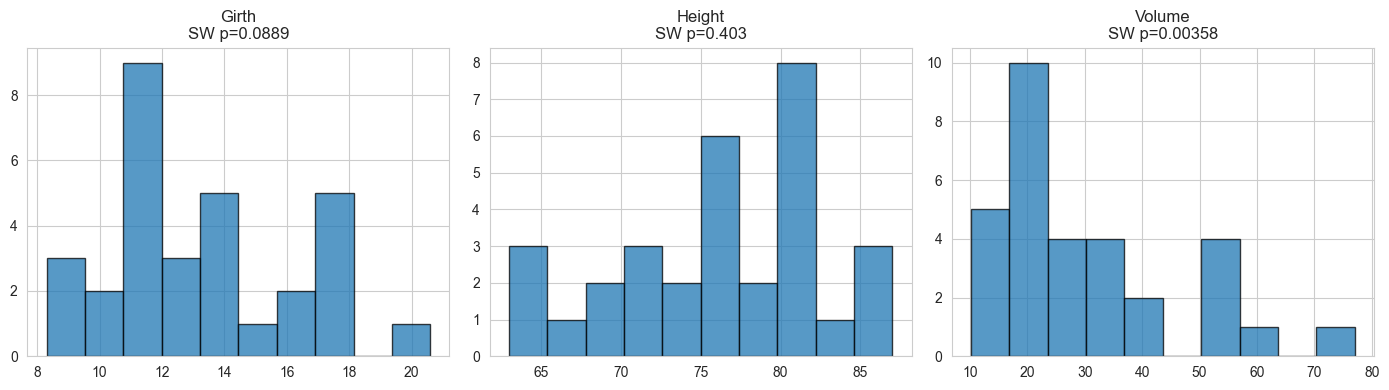

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, cols):
    ax.hist(trees[col], bins=10, edgecolor="k", alpha=0.75)
    ax.set_title(f"{col}\nSW p={sw[col][1]:.3g}")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "trees_hist.png"), dpi=120)
plt.show()

---
## 4–5. Данные `randu`

`randu` — 400 троек псевдослучайных чисел из [0,1], столбцы `x, y, z`.

**5a.** Двувыборочный KS: H0 — все три из одного непрерывного распределения.  
**5b.** KS goodness-of-fit: `x ~ N`, `y ~ U(0,1)`.

In [8]:
hr("4-5. ДАННЫЕ randu")
randu = load_csv("datasets/randu")
randu = randu.drop(columns=[c for c in randu.columns if c.lower().startswith("row")],
                   errors="ignore")
print("Столбцы:", list(randu.columns), "| форма:", randu.shape)
randu.head()


4-5. ДАННЫЕ randu
Столбцы: ['x', 'y', 'z'] | форма: (400, 3)


,x,y,z
0,0.000031,0.000183,0.000824
1,0.044495,0.155732,0.533939
2,0.822440,0.873416,0.838542
3,0.322291,0.648545,0.990648
4,0.393595,0.826873,0.418881


In [10]:
x, y, z = randu["x"].values, randu["y"].values, randu["z"].values

print("[5a] Двувыборочный KS: H0 — выборки из одного непрерывного распределения")
for (n1, a), (n2, b) in [(("x", x), ("y", y)),
                         (("x", x), ("z", z)),
                         (("y", y), ("z", z))]:
    D, p = stats.ks_2samp(a, b)
    print(f"  {n1} vs {n2}: D={D:.4f}, p={p:.4g}  → {verdict(p)}")

[5a] Двувыборочный KS: H0 — выборки из одного непрерывного распределения
  x vs y: D=0.0850, p=0.1111  → H0 НЕ отвергается (p>alpha)
  x vs z: D=0.0875, p=0.09352  → H0 НЕ отвергается (p>alpha)
  y vs z: D=0.0475, p=0.7583  → H0 НЕ отвергается (p>alpha)


**Объяснение п.5a.** Двувыборочный KS-тест сравнивает **одномерные эмпирические функции распределения**. У `randu` маргинальные распределения `x, y, z` близки к равномерному U(0,1), поэтому H0 о «едином непрерывном распределении» **не отвергается** — что не противоречит известному дефекту RANDU: его тройки лежат на плоскостях в 3D, но одномерные маргиналы при этом остаются равномерными.

In [11]:
print("[5b] Одновыборочный KS (согласие с законом)")
mu_x, sd_x = x.mean(), x.std(ddof=1)
D, p = stats.kstest(x, "norm", args=(mu_x, sd_x))
print(f"  x ~ N(mu={mu_x:.3f}, sd={sd_x:.3f}): D={D:.4f}, p={p:.4g}  → {verdict(p)}")

D, p = stats.kstest(y, "uniform", args=(0, 1))
print(f"  y ~ U(0,1): D={D:.4f}, p={p:.4g}  → {verdict(p)}")

print("\n[контроль]")
D, p = stats.kstest(x, "uniform", args=(0, 1))
print(f"  x ~ U(0,1): D={D:.4f}, p={p:.4g}  → {verdict(p)}")
D, p = stats.kstest(y, "norm", args=(y.mean(), y.std(ddof=1)))
print(f"  y ~ N: D={D:.4f}, p={p:.4g}  → {verdict(p)}")

[5b] Одновыборочный KS (согласие с законом)
  x ~ N(mu=0.526, sd=0.285): D=0.0733, p=0.02569  → H0 отвергается (p<=alpha)
  y ~ U(0,1): D=0.0357, p=0.6739  → H0 НЕ отвергается (p>alpha)

[контроль]
  x ~ U(0,1): D=0.0555, p=0.1635  → H0 НЕ отвергается (p>alpha)
  y ~ N: D=0.0713, p=0.03241  → H0 отвергается (p<=alpha)


**Объяснение п.5b.** `x` равномерно на [0,1], поэтому H0 о нормальности **отвергается**; `y` — равномерно, H0 о U(0,1) **не отвергается**. Контрольные проверки подтверждают интерпретацию.

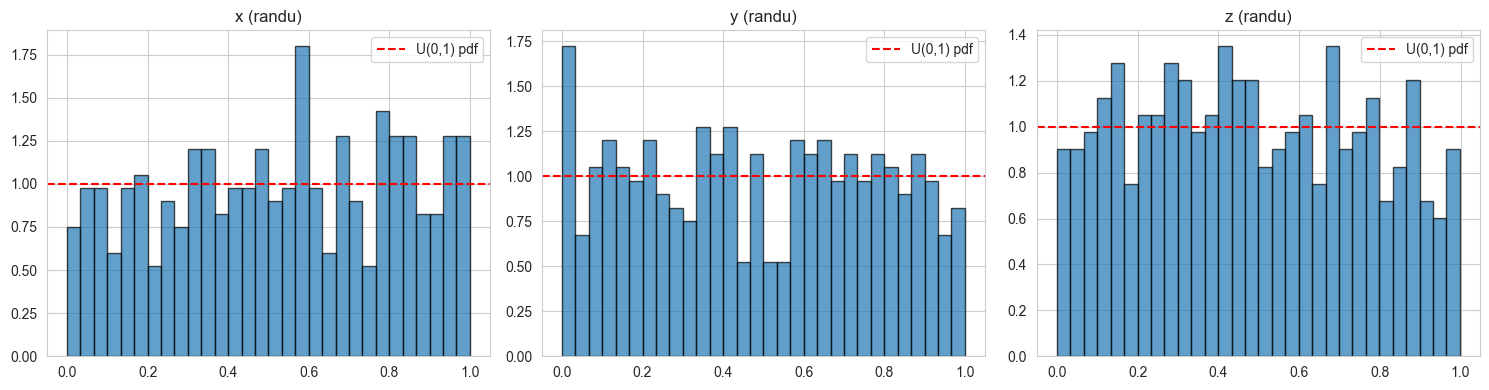

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, v) in zip(axes, [("x", x), ("y", y), ("z", z)]):
    ax.hist(v, bins=30, density=True, alpha=0.7, edgecolor="k")
    ax.axhline(1.0, color="r", ls="--", label="U(0,1) pdf")
    ax.set_title(f"{name} (randu)")
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "randu_hist.png"), dpi=120)
plt.show()

---
## 6–8. Данные `ldeaths`

`ldeaths` — временной ряд (в R: `class(ldeaths) == "ts"`).  
**7.** t-тест средних по годам.  
**8.** Критерий Фишера (равенство дисперсий) по годам.

In [13]:
hr("6-8. ДАННЫЕ ldeaths")
ldeaths = load_csv("datasets/ldeaths", local_file="ldeaths.csv")
ldeaths = ldeaths.drop(columns=[c for c in ldeaths.columns if c.lower().startswith("row")],
                       errors="ignore")
print("Столбцы:", list(ldeaths.columns))
ldeaths.head()


6-8. ДАННЫЕ ldeaths
Столбцы: ['time', 'value']


,time,value
0,1974.000000,3035
1,1974.083333,2552
2,1974.166667,2704
3,1974.250000,2554
4,1974.333333,2014


In [14]:
ldeaths["year"] = ldeaths["time"].astype(float).astype(int)
years = sorted(ldeaths["year"].unique())
print("[6] Годы:", years)
print("    dtype time:", ldeaths["time"].dtype, "| шаг постоянный:",
      np.allclose(np.diff(np.sort(ldeaths["time"].unique())),
                  np.diff(np.sort(ldeaths["time"].unique()))[0]))

[6] Годы: [np.int64(1974), np.int64(1975), np.int64(1976), np.int64(1977), np.int64(1978), np.int64(1979)]
    dtype time: float64 | шаг постоянный: True


In [15]:
groups = {yr: ldeaths.loc[ldeaths["year"] == yr, "value"].values for yr in years}
print("[7] t-тест Стьюдента: равенство средних смертности между годами")
print("Средние по годам:")
for yr in years:
    print(f"  {yr}: mean={groups[yr].mean():8.2f}  sd={groups[yr].std(ddof=1):8.2f}")

print("\n  Попарные t-тесты (Уэлч):")
for i in range(len(years)):
    for j in range(i + 1, len(years)):
        t, p = stats.ttest_ind(groups[years[i]], groups[years[j]], equal_var=False)
        print(f"  {years[i]} vs {years[j]}: t={t:7.3f}, p={p:.4g}  → {verdict(p)}")

F, p = stats.f_oneway(*[groups[yr] for yr in years])
print(f"\n  [бонус] One-way ANOVA: F={F:.4f}, p={p:.4g}  → {verdict(p)}")

[7] t-тест Стьюдента: равенство средних смертности между годами
Средние по годам:
  1974: mean= 2178.33  sd=  494.60
  1975: mean= 2175.08  sd=  602.25
  1976: mean= 2143.17  sd=  831.87
  1977: mean= 1935.75  sd=  552.08
  1978: mean= 1995.92  sd=  621.57
  1979: mean= 1911.50  sd=  572.25

  Попарные t-тесты (Уэлч):
  1974 vs 1975: t=  0.014, p=0.9886  → H0 НЕ отвергается (p>alpha)
  1974 vs 1976: t=  0.126, p=0.9012  → H0 НЕ отвергается (p>alpha)
  1974 vs 1977: t=  1.134, p=0.2693  → H0 НЕ отвергается (p>alpha)
  1974 vs 1978: t=  0.796, p=0.4352  → H0 НЕ отвергается (p>alpha)
  1974 vs 1979: t=  1.222, p=0.2349  → H0 НЕ отвергается (p>alpha)
  1975 vs 1976: t=  0.108, p=0.9153  → H0 НЕ отвергается (p>alpha)
  1975 vs 1977: t=  1.015, p=0.3213  → H0 НЕ отвергается (p>alpha)
  1975 vs 1978: t=  0.717, p=0.4809  → H0 НЕ отвергается (p>alpha)
  1975 vs 1979: t=  1.099, p=0.2836  → H0 НЕ отвергается (p>alpha)
  1976 vs 1977: t=  0.720, p=0.4804  → H0 НЕ отвергается (p>alpha)
  1976 vs 

In [16]:
print("[8] Критерий Фишера: равенство дисперсий между годами")
for i in range(len(years)):
    for j in range(i + 1, len(years)):
        F, p, dfn, dfd = f_test(groups[years[i]], groups[years[j]])
        print(f"  {years[i]} vs {years[j]}: F={F:8.4f}, df=({dfn},{dfd}), "
              f"p={p:.4g}  → {verdict(p)}")

[8] Критерий Фишера: равенство дисперсий между годами
  1974 vs 1975: F=  0.6744, df=(11,11), p=0.5245  → H0 НЕ отвергается (p>alpha)
  1974 vs 1976: F=  0.3535, df=(11,11), p=0.09879  → H0 НЕ отвергается (p>alpha)
  1974 vs 1977: F=  0.8026, df=(11,11), p=0.7218  → H0 НЕ отвергается (p>alpha)
  1974 vs 1978: F=  0.6332, df=(11,11), p=0.4607  → H0 НЕ отвергается (p>alpha)
  1974 vs 1979: F=  0.7470, df=(11,11), p=0.6369  → H0 НЕ отвергается (p>alpha)
  1975 vs 1976: F=  0.5241, df=(11,11), p=0.299  → H0 НЕ отвергается (p>alpha)
  1975 vs 1977: F=  1.1900, df=(11,11), p=0.778  → H0 НЕ отвергается (p>alpha)
  1975 vs 1978: F=  0.9388, df=(11,11), p=0.9185  → H0 НЕ отвергается (p>alpha)
  1975 vs 1979: F=  1.1076, df=(11,11), p=0.8684  → H0 НЕ отвергается (p>alpha)
  1976 vs 1977: F=  2.2705, df=(11,11), p=0.1896  → H0 НЕ отвергается (p>alpha)
  1976 vs 1978: F=  1.7912, df=(11,11), p=0.348  → H0 НЕ отвергается (p>alpha)
  1976 vs 1979: F=  2.1132, df=(11,11), p=0.2303  → H0 НЕ отвергаетс

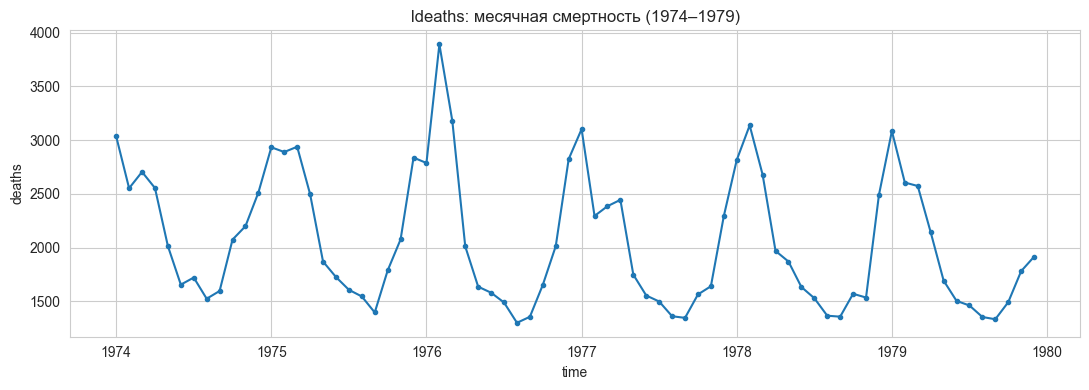

In [17]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ldeaths["time"], ldeaths["value"], "-o", ms=3)
ax.set_xlabel("time"); ax.set_ylabel("deaths")
ax.set_title("ldeaths: месячная смертность (1974–1979)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "ldeaths_ts.png"), dpi=120)
plt.show()

**Вывод по п.7.** Если p > 0.05 — нет оснований отвергать H0 о равенстве средних между соответствующими годами; иначе средние значимо различаются. One-way ANOVA даёт общий ответ «все ли средние равны».

**Вывод по п.8.** F-тест сравнивает дисперсии попарно; p > 0.05 — дисперсии неразличимы. Напоминание: F-тест чувствителен к отклонению от нормальности.

---
## 9–12. Данные `HairEyeColor`

В R это 3D-таблица `Hair × Eye × Sex`. Ниже используются опубликованные счётчики (Snee, 1974), разложенные на `male` и `female` — это те же числа, что и в `HairEyeColor`.

**10.** Пирсон χ² для мужчин.  
**11.** Пирсон χ² для женщин.  
**12.** Мозаичные диаграммы.

In [18]:
hr("9-12. ДАННЫЕ HairEyeColor")

male = pd.DataFrame(
    [[32, 11, 10, 3],
     [38, 50, 25, 15],
     [10, 25, 7, 7],
     [3, 15, 7, 8]],
    index=["Black", "Brown", "Red", "Blond"],
    columns=["Brown", "Blue", "Hazel", "Green"],
)
female = pd.DataFrame(
    [[36, 9, 5, 2],
     [66, 34, 29, 14],
     [16, 7, 7, 7],
     [4, 36, 6, 16]],
    index=["Black", "Brown", "Red", "Blond"],
    columns=["Brown", "Blue", "Hazel", "Green"],
)

print("[10] male: Hair × Eye")
print(male)
chi2, p, dof, exp = stats.chi2_contingency(male)
print(f"\nchi2={chi2:.3f}, df={dof}, p={p:.4g}  → {verdict(p)}")
print("Минимальная ожидаемая частота:", exp.min().round(2))


9-12. ДАННЫЕ HairEyeColor
[10] male: Hair × Eye
       Brown  Blue  Hazel  Green
Black     32    11     10      3
Brown     38    50     25     15
Red       10    25      7      7
Blond      3    15      7      8

chi2=33.698, df=9, p=0.0001009  → H0 отвергается (p<=alpha)
Минимальная ожидаемая частота: 4.09


In [19]:
print("[11] female: Hair × Eye")
print(female)
chi2f, pf, doff, expf = stats.chi2_contingency(female)
print(f"\nchi2={chi2f:.3f}, df={doff}, p={pf:.4g}  → {verdict(pf)}")
print("Минимальная ожидаемая частота:", expf.min().round(2))

def cramers_v(tab, chi2):
    n = tab.values.sum()
    r, k = tab.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

print("\n[бонус] Cramér's V:")
print(f"  male  : {cramers_v(male, chi2):.3f}")
print(f"  female: {cramers_v(female, chi2f):.3f}")

[11] female: Hair × Eye
       Brown  Blue  Hazel  Green
Black     36     9      5      2
Brown     66    34     29     14
Red       16     7      7      7
Blond      4    36      6     16

chi2=69.445, df=9, p=1.956e-11  → H0 отвергается (p<=alpha)
Минимальная ожидаемая частота: 4.91

[бонус] Cramér's V:
  male  : 0.205
  female: 0.281


**Вывод по п.10–11.** Если `p <= 0.05`, гипотеза о независимости цвета глаз и цвета волос **отвергается** — признаки связаны. Cramér's V показывает силу связи (0 — независимость, 1 — максимальная). Обычно у обоих полов связь есть, но её сила и структура (какие именно комбинации чаще) различаются.

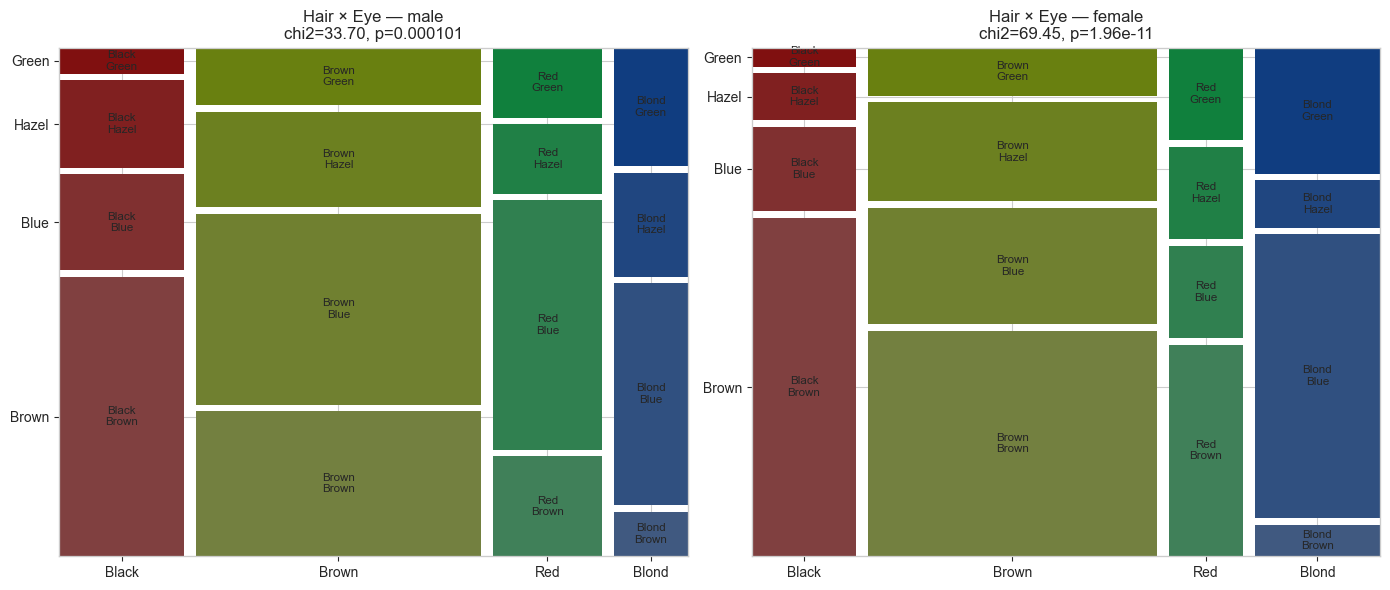

In [21]:


fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, tab) in zip(axes, [("male", male), ("female", female)]):
    data = {(str(i), str(j)): tab.loc[i, j] for i in tab.index for j in tab.columns}
    chi2_, p_ = stats.chi2_contingency(tab)[:2]
    mosaic(data, ax=ax, gap=0.02,
           title=f"Hair × Eye — {name}\nchi2={chi2_:.2f}, p={p_:.3g}")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "hair_eye_mosaic.png"), dpi=120)
plt.show()

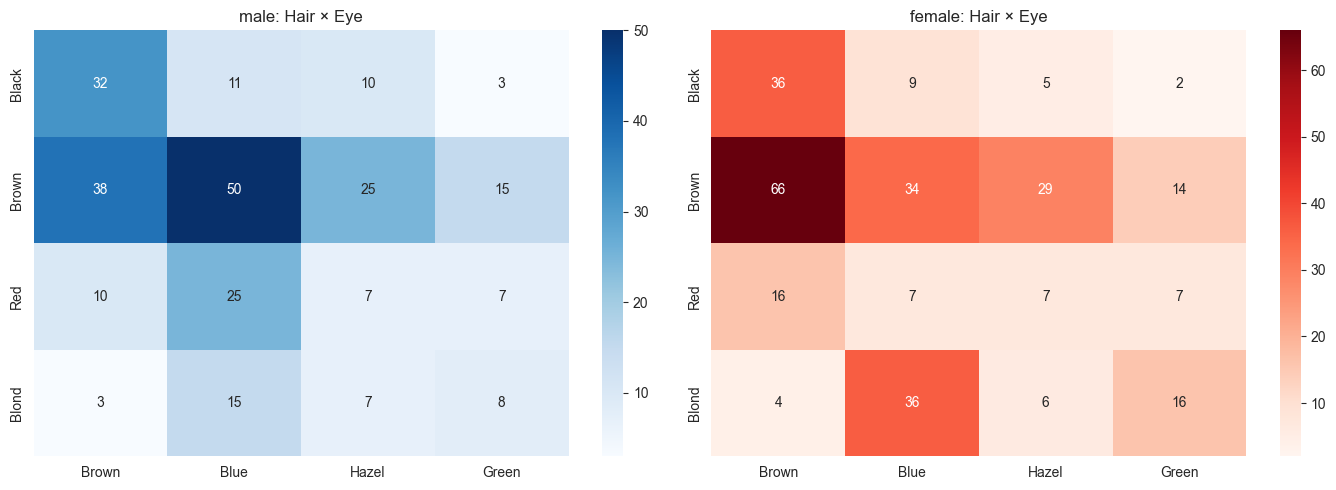

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(male, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("male: Hair × Eye")
sns.heatmap(female, annot=True, fmt="d", cmap="Reds", ax=axes[1])
axes[1].set_title("female: Hair × Eye")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "hair_eye_heatmap.png"), dpi=120)
plt.show()

**Вывод по п.12.** Мозаика показывает совместные пропорции: более высокие/широкие блоки соответствуют более частым сочетаниям. Сравнивая `male` и `female`, видно, что структура связи «цвет волос ↔ цвет глаз» похожа (тёмные волосы чаще с карими глазами, светлые — с голубыми), но пропорции различаются.

---
## Итоговая сводка

| Пункт | Что сделано |
|---|---|
| 1 | Выведены имена столбцов `trees` |
| 2 | Shapiro–Wilk по каждому столбцу + вывод |
| 3 | Критерий Фишера для **всех пар** столбцов `trees` |
| 4 | Загружен `randu`, разобран на `x, y, z` |
| 5 | KS 2-sample для (x,y),(x,z),(y,z); KS gof: `x~N`, `y~U(0,1)` |
| 6 | Загружен `ldeaths`, выделен год |
| 7 | Попарные t-тесты (Уэлч) + бонус ANOVA |
| 8 | Попарные F-тесты по годам |
| 9–11 | Таблицы `male`/`female`, χ² Пирсона + Cramér's V |
| 12 | Мозаика + heatmap |

Все графики сохранены в каталог `output/`.